In [3]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras import regularizers
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
(xtrain,_),(xtest,_)=tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [4]:
train=pd.read_csv("mnist_train.csv")
test = pd.read_csv('mnist_test.csv')

In [6]:
x_train = train.iloc[:,1:].values
x_test = test.iloc[:,1:].values
x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

In [7]:
encoding_dim=32

In [10]:
input_img = Input(shape=(784,))

In [11]:
encoded = Dense(encoding_dim,activation='relu',activity_regularizer=regularizers.l1(10e-5))(input_img)

In [12]:
decoded = Dense(784,activation='sigmoid')(encoded)

In [13]:
autoencoder=Model(inputs=input_img,outputs=decoded)

In [14]:
autoencoder.compile(optimizer='adam',loss='mse')

In [15]:
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 784)            │        25,872 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,992 (199.19 KB)

 Trainable params: 50,992 (199.19 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history = autoencoder.fit(x_train,x_train,epochs=5,batch_size=256,shuffle=True,validation_data=(x_test,x_test))

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0777 - val_loss: 0.0463
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0399 - val_loss: 0.0347
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0322 - val_loss: 0.0294
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0280 - val_loss: 0.0260
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0250 - val_loss: 0.0234


In [17]:
reconstructed_imgs = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [18]:
n=10
plt.figure(figsize=(20,4))

<Figure size 2000x400 with 0 Axes>

<Figure size 2000x400 with 0 Axes>

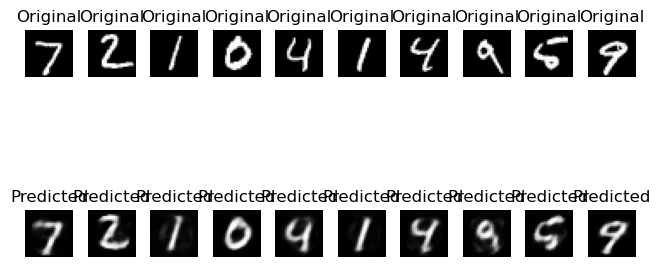

In [19]:
for i in range(n):
    ax = plt.subplot(2,n,i+1)
    plt.imshow(x_test[i].reshape(28,28),cmap='gray')
    plt.title("Original")
    plt.axis('off')

    ax=plt.subplot(2,n,i+1+n)
    plt.imshow(reconstructed_imgs[i].reshape(28,28),cmap='gray')
    plt.title("Predicted")
    plt.axis('off')
plt.tight_layout()
plt.show()